# Pre-process

## Importations

### Import library

In [22]:
# Maths use
import numpy as np
import math 

#Data
import pandas as pd

#Graphiques
import seaborn as sns
sns.set()
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as gp

### Import data set

In [23]:
data = pd.read_csv("disney_data.csv")

## Data exploration 

In [24]:
display(data.head())

,customer_id,age,gender,country,region,signup_date,tenure_months,subscription_type,monthly_fee,promo_used,...,avg_watch_time_per_day,avg_session_minutes,sessions_per_month,last_login_days,support_tickets,satisfaction_score,lifetime_revenue,churned,churn_date,churn_reason
0,7e294f9f-8222-45b8-a3a9-6ba4583f6e16,44.0,Other,United States,North America,2022-10-18,9,Premium,17.99,Yes,...,0.12,23.0,10,45,0,5.0,129.53,1,2023-07-08,Not enough content
1,2a496a84-3d5c-4f06-bd48-da1f949c04e5,27.0,Other,Australia,Oceania,2021-09-13,15,Premium,17.99,No,...,0.08,21.0,7,30,0,8.0,269.85,1,2022-12-09,Price too high
2,5b1242bc-0dbb-4018-8f9d-33376f5b1092,46.0,Female,Colombia,South America,2025-10-12,12,Basic,8.99,No,...,0.36,54.0,12,16,1,6.0,107.88,0,NaN,NaN
3,4aaa4b30-0995-42b2-86f8-acd420bd1f27,65.0,Other,India,Asia,2025-06-03,14,Standard,13.99,Yes,...,0.08,49.0,4,41,0,6.0,156.69,1,2026-08-19,Poor streaming quality
4,b942a90e-e80a-4079-94cf-b6657f127de4,33.0,Male,United States,North America,2026-05-23,4,Premium,17.99,No,...,0.01,51.0,1,15,0,3.0,71.96,0,NaN,NaN


In [31]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 12060 entries, 0 to 12059
Data columns (total 29 columns):
 #   Column                  Non-Null Count  Dtype         
---  ------                  --------------  -----         
 0   customer_id             12060 non-null  object        
 1   age                     11916 non-null  float64       
 2   gender                  12060 non-null  object        
 3   country                 12060 non-null  object        
 4   region                  12060 non-null  object        
 5   signup_date             12060 non-null  datetime64[ns]
 6   tenure_months           12060 non-null  int64         
 7   subscription_type       12060 non-null  object        
 8   monthly_fee             12060 non-null  float64       
 9   promo_used              12060 non-null  object        
 10  discount_percent        12060 non-null  int64         
 11  acquisition_channel     12060 non-null  object        
 12  payment_method          11879 non-null  object

In [26]:
data["churn_date"] = pd.to_datetime(data["churn_date"])
data["signup_date"] = pd.to_datetime(data["signup_date"])

In [27]:
print("Number of clients:", data.shape[0])
print("Number of features:", data.shape[1])

Number of clients: 12060
Number of features: 29


### NA detection 

In [28]:
print("Number of Nan values:")
display(data.isna().sum().where(lambda x: x > 0).dropna())

Number of Nan values:


age                     144.0
payment_method          181.0
avg_session_minutes     240.0
satisfaction_score      844.0
churn_date             7230.0
churn_reason           7230.0
dtype: float64

### Data process for qualitative feature 

Class of each features

In [29]:
for col in data.select_dtypes(include='object').columns:
    quali_mat = pd.DataFrame({
        "Value Count" : data[col].value_counts()
    })
    display(quali_mat)

,Value Count
customer_id,
ca75f885-2393-40f3-bd87-28f761ef8487,2
43536836-05b1-4464-a77b-78d6e8916b79,2
1acacfa3-e370-4855-9b8c-bfd6d733ec7b,2
51efc330-55c5-4b72-98ef-7bb6c3a82162,2
3bea04a9-f8bc-4696-b3bb-60ebd979b047,2
...,...
2ef8917f-008f-4cda-ac07-1c700c111afd,1
7801bca7-2293-477b-90dc-2db2fff6a041,1
f0432d3c-5c75-4cca-b27c-73f92ef194cb,1


,Value Count
gender,
Female,4074
Male,3951
Other,3891
male,50
F,49
other,45


,Value Count
country,
United States,1408
Brazil,1282
New Zealand,906
Australia,883
United Kingdom,813
India,728
Japan,525
Egypt,490
Nigeria,484


,Value Count
region,
South America,2149
Europe,2133
North America,2089
Asia,1991
Africa,1909
Oceania,1789


,Value Count
subscription_type,
Premium,4193
Standard,4038
Basic,3829


...

,Value Count
payment_method,
Debit Card,2523
PayPal,2433
Credit Card,2388
Crypto,2273
Gift Card,2262


,Value Count
auto_renew,
Yes,8914
No,3146


,Value Count
device,
Tablet,2519
Laptop,2395
TV,2392
Mobile,2387
Desktop,2247
tablet,27
laptop,27
mobile,26
desktop,21


,Value Count
favorite_genre,
Documentary,1814
Sci-Fi,1788
Romance,1777
Drama,1733
Horror,1726
Action,1618
Comedy,1604


,Value Count
churn_reason,
Price too high,1054
Not enough content,951
Switched to competitor,794
Billing problems,711
Poor streaming quality,467
Technical issues,457
Other,396


We see that there is some category that are not properly filled in, so we are getting that sorted out.

In [47]:
data["gender"] = data["gender"].replace({"male": "Male", "other": "Other", "F " : "Female"})
data["device"] = data["device"].replace({"tablet": "Tablet", "laptop": "Laptop", "mobile": "Mobile", "desktop": "Desktop", "tv": "TV", "other": "Other"})


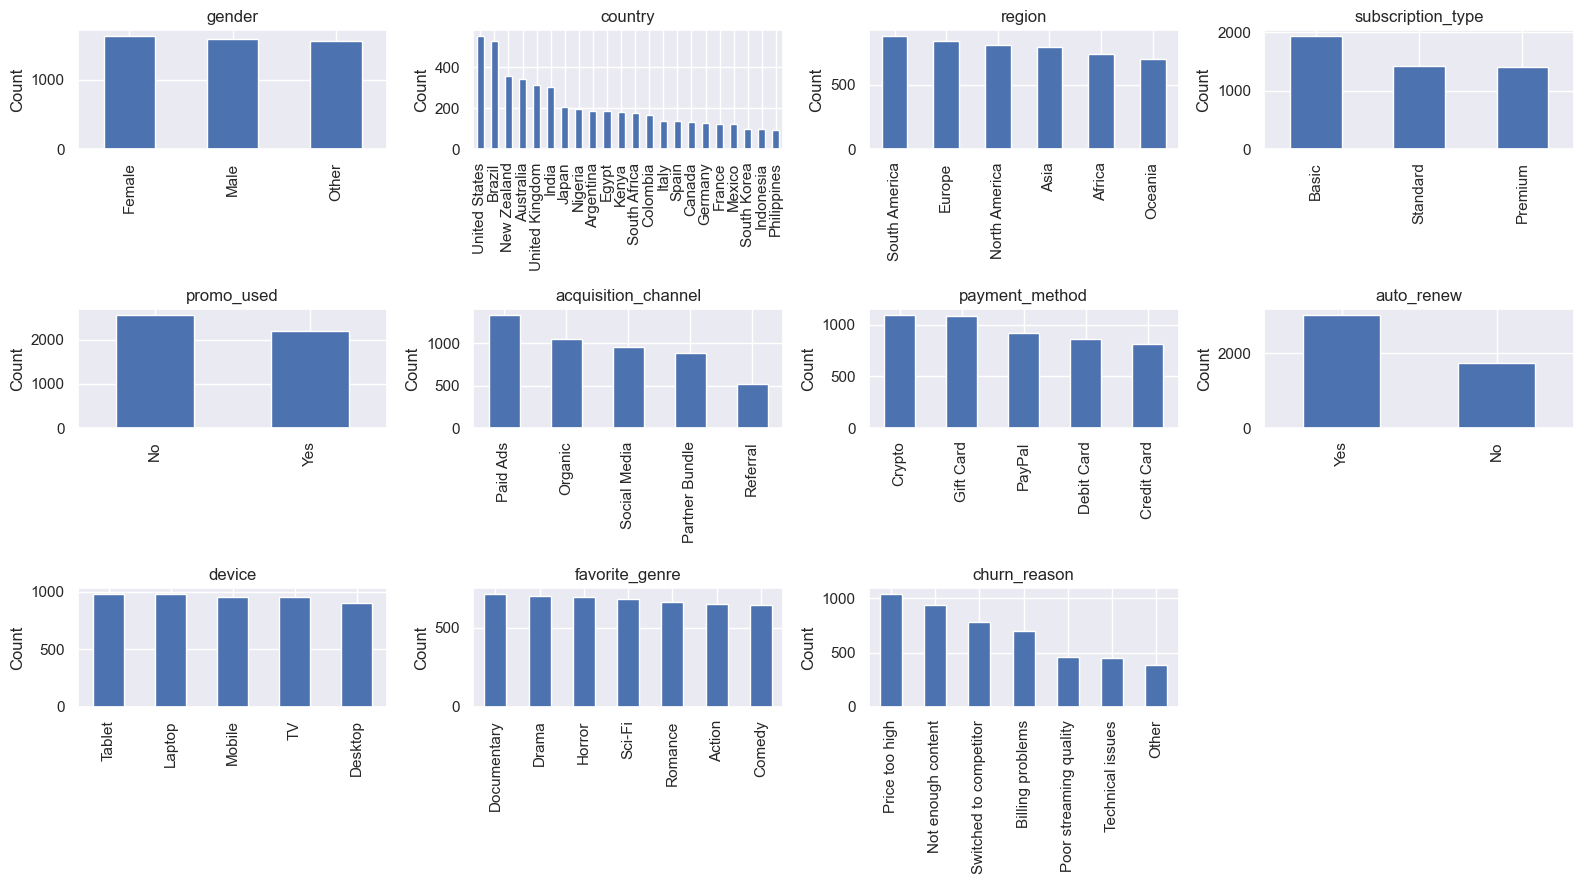

In [48]:
features = data.select_dtypes('object').drop(columns=['customer_id']).dropna()
ncols = 4
nrows = (len(features.columns) + ncols - 1) // ncols
fig, axes = plt.subplots(nrows, ncols, figsize=(4 * ncols, 3 * nrows), squeeze=False)

for ax, (name, values) in zip(axes.flat, features.items()):
    values.value_counts(dropna=False).plot.bar(ax=ax)
    ax.set(title=name, xlabel='', ylabel='Count')

for ax in axes.flat[len(features.columns):]:
    ax.set_visible(False)

fig.tight_layout()
plt.show()

In [ ]:
missing = data[['churn_date', 'churn_reason']].isna()
tableau_nan = missing.sum().to_frame('Number of NaN in data')
tableau_nan['Number of NaN among non-churned customers'] = missing[data['churned'].eq(0)].sum()
tableau_nan = tableau_nan.rename_axis('feature').reset_index()

display(tableau_nan)

,feature,Number of NaN in data,Number of NaN among non-churned customers
0,churn_date,7230,7230
1,churn_reason,7230,7230


Then we can deal with NA value without considering it as a problem. As all client that have not unsubscribed as NA value in those 2 columns. 

#### NA for payement_method

In [ ]:
#Payement method by churned customers
payment_mth = (
    data.groupby(['payment_method', 'churned'])
        .size()
        .unstack(fill_value=0)
        .rename(columns={
            0: 'Non-churned customers',
            1: 'Churned customers'
        })
)

display(payment_mth)

churned,Non-churned customers,Churned customers
payment_method,,
Credit Card,1578,810
Crypto,1180,1093
Debit Card,1664,859
Gift Card,1176,1086
PayPal,1517,916


In [ ]:
pay_chr = pd.crosstab(
    data['churned'],
    data['payment_method'].isna(),
    margins=True
)

pay_chr = pay_chr.reindex(
    index=[0, 1, 'All'],
    columns=[False, True, 'All'],
    fill_value=0
)

pay_chr.columns = [
    'Payment method known',
    'Payment method unknown',
    'All'
]

pay_chr.index = [
    'Non-churned customers',
    'Churned customers',
    'All'
]

display(pay_chr)

,Payment method known,Payment method unknown,All
Non-churned customers,7115,115,7230
Churned customers,4764,66,4830
All,11879,181,12060


We disided to creat a new class for NA values in payement method and we name it "Unknown" as we belive all this individuals are important. 

In [ ]:
data['payment_method'] = data['payment_method'].fillna('Unknown')

display(data['payment_method'].value_counts())

payment_method
Debit Card     2523
PayPal         2433
Credit Card    2388
Crypto         2273
Gift Card      2262
Unknown         181
Name: count, dtype: int64

#### NA for age

In [ ]:
display(data['age'].describe())

count    11916.000000
mean        44.004951
std         17.991103
min         -1.000000
25%         30.000000
50%         44.000000
75%         58.000000
max        999.000000
Name: age, dtype: float64

In [ ]:
display(data[(data['age'] >= 90) | (data['age'] <= 15)]['age'])

1048       3.0
3129     150.0
5236     140.0
5247      -1.0
5902       7.0
6028     130.0
7054     200.0
7601       0.0
8035     999.0
8387       2.0
10090      5.0
10246    120.0
Name: age, dtype: float64

There is 12 clients that have aberante values. We prefer to remove it as we can not know if this is a mistake or juste false data. They represent 0.10 %, so it would not affect our models.